<a href="https://colab.research.google.com/github/jessisam2007/24BAD049_24ADI006-DeepLearning/blob/main/EX_7_Autoencoder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPT NO: 7
## Implementation of a Simple Autoencoder for Dimensionality Reduction and Feature Learning
**Roll No:** 24BAD049

## PART A: Dataset Preparation

Roll No: 24BAD049
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Dataset Exploration ---
Training set shape : (60000, 28, 28)
Testing set shape  : (10000, 28, 28)
Single image shape : (28, 28)
Data type          : uint8
Pixel range        : 0 to 255

After normalization -> dtype: float32 | range: 0.0 to 1.0
After reshaping -> train: (60000, 784) | test: (10000, 784)
Targets equal inputs -> train: (60000, 784) | test: (10000, 784)


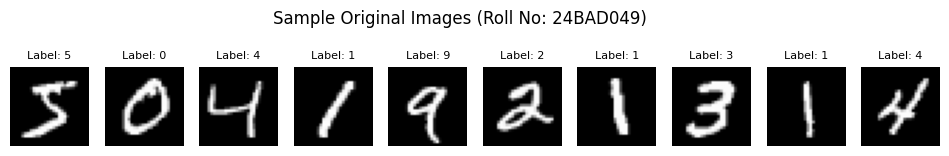

In [1]:
# Roll No: 24BAD049

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

print("Roll No: 24BAD049")

# 1. Load the MNIST dataset (already split into training and testing sets)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Explore the dataset: dimensions and data types
print("\n--- Dataset Exploration ---")
print("Training set shape :", x_train.shape)
print("Testing set shape  :", x_test.shape)
print("Single image shape :", x_train.shape[1:])
print("Data type          :", x_train.dtype)
print("Pixel range        :", x_train.min(), "to", x_train.max())

# 3. Normalize pixel values from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("\nAfter normalization -> dtype:", x_train.dtype,
      "| range:", x_train.min(), "to", x_train.max())

# 4. Reshape 28x28 images into 784-length vectors (Dense Autoencoder)
x_train = x_train.reshape(len(x_train), 28 * 28)
x_test = x_test.reshape(len(x_test), 28 * 28)
print("After reshaping -> train:", x_train.shape, "| test:", x_test.shape)

# 5. Input data is also the target output for reconstruction
target_train = x_train
target_test = x_test
print("Targets equal inputs -> train:", target_train.shape, "| test:", target_test.shape)

# 6. Display a sample of the original images
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_train[i]}", fontsize=8)
    plt.axis("off")
plt.suptitle("Sample Original Images (Roll No: 24BAD049)")
plt.show()

## PART B: Implementing the Autoencoder Model

Roll No: 24BAD049


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

... (6 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Dense)          │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)

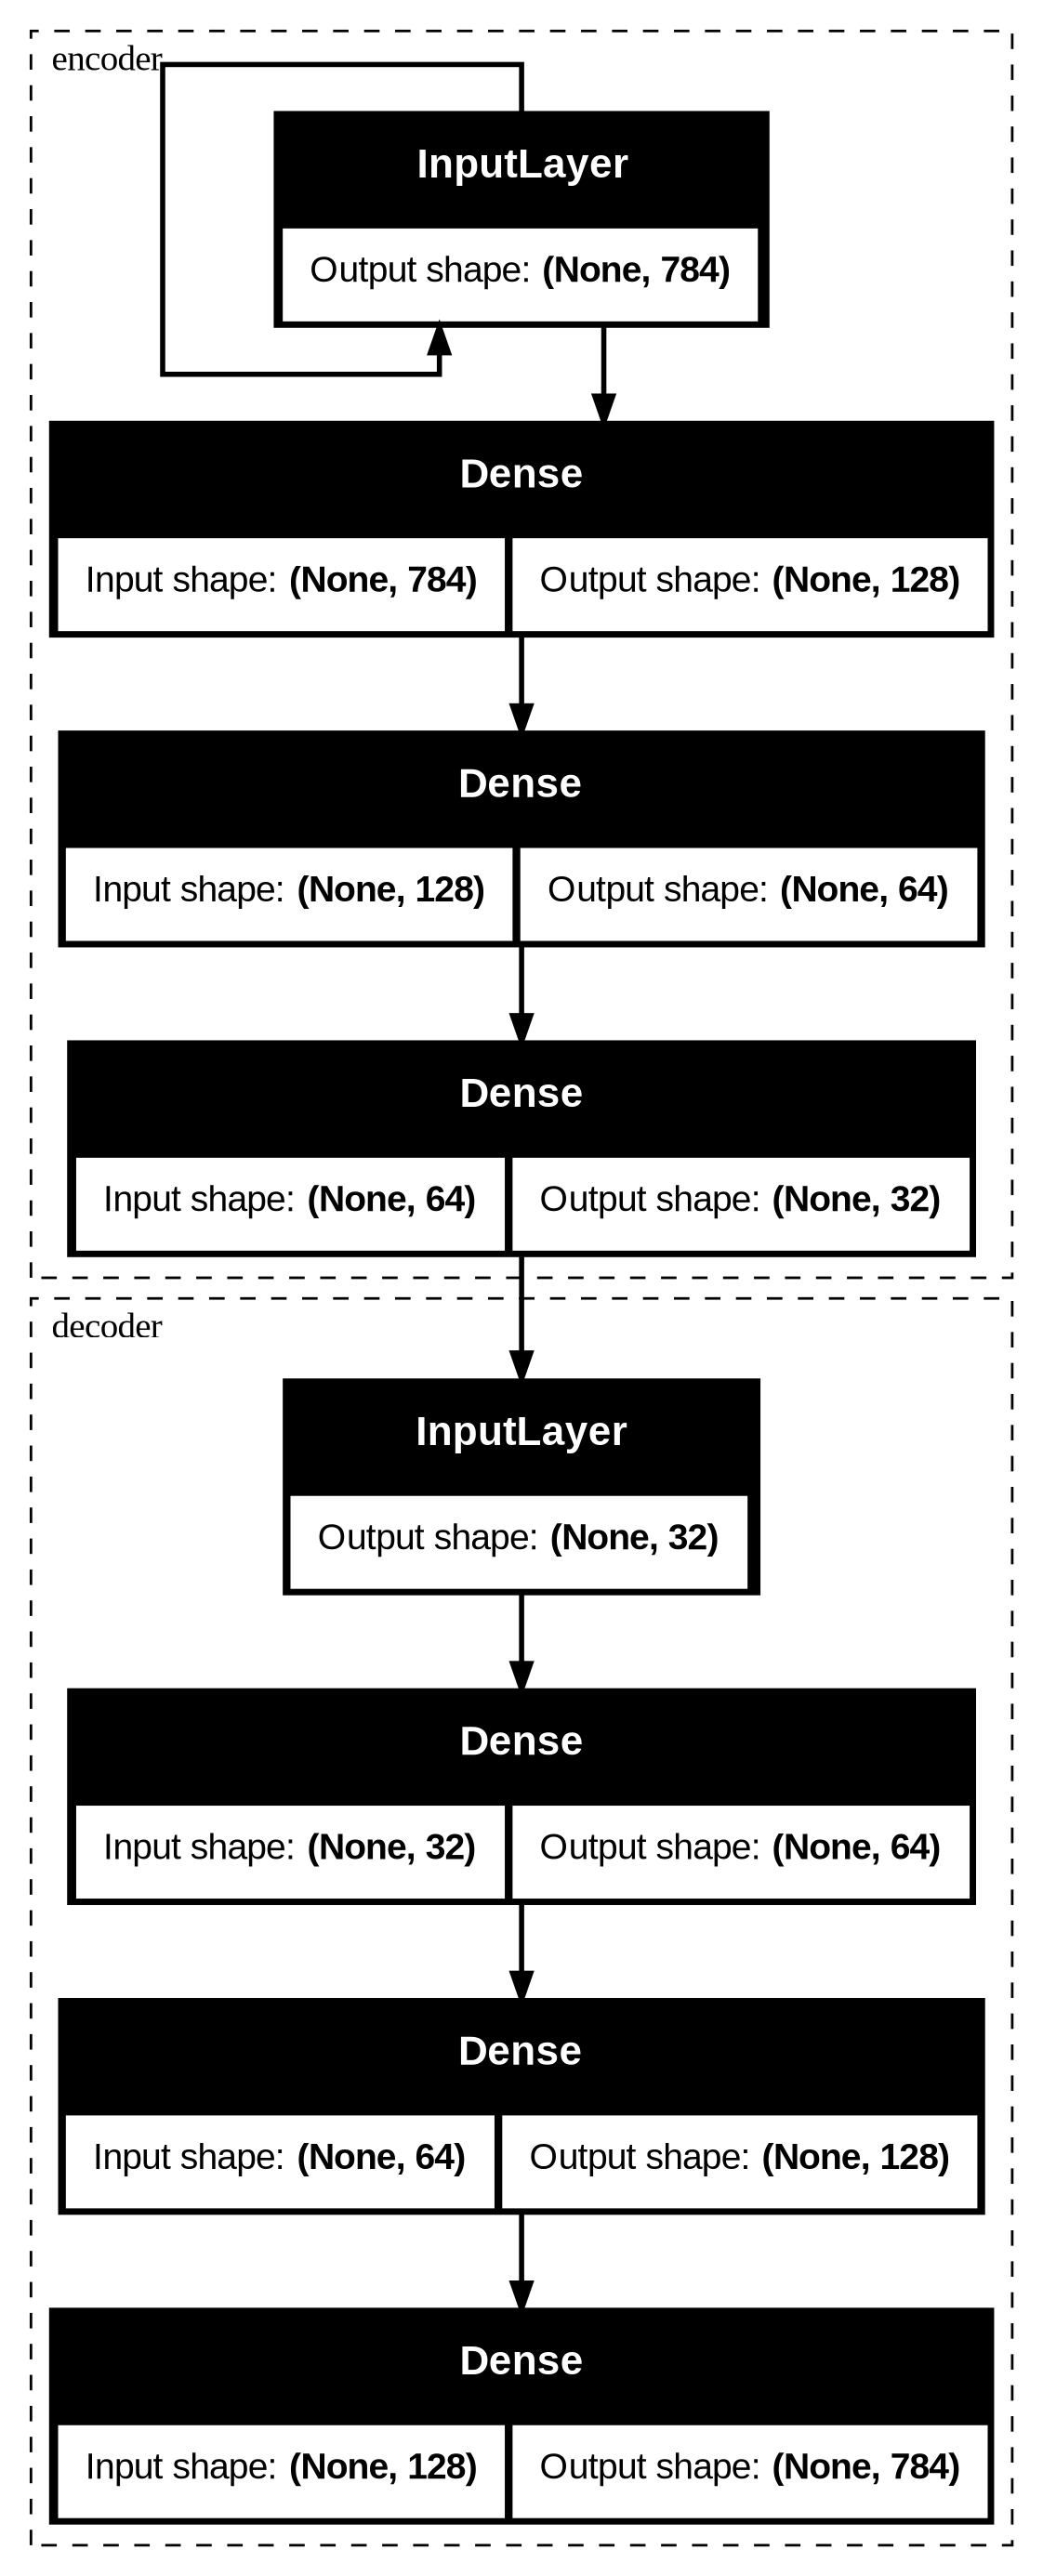

In [2]:
# Roll No: 24BAD049

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

print("Roll No: 24BAD049")

# 1. Input layer based on dataset dimensions (784 features)
input_dim = x_train.shape[1]
encoding_dim = 32          # bottleneck size (much smaller than 784)
input_layer = Input(shape=(input_dim,), name="input_layer")

# 2. Encoder: Dense layers with ReLU
x = Dense(128, activation="relu", name="encoder_dense_1")(input_layer)
x = Dense(64, activation="relu", name="encoder_dense_2")(x)

# 3. Bottleneck layer: fewer neurons than the input layer
bottleneck = Dense(encoding_dim, activation="relu", name="bottleneck")(x)
encoder = Model(input_layer, bottleneck, name="encoder")

# 4. Decoder: reconstructs the input from the bottleneck representation
decoder_input = Input(shape=(encoding_dim,), name="decoder_input")
d = Dense(64, activation="relu", name="decoder_dense_1")(decoder_input)
d = Dense(128, activation="relu", name="decoder_dense_2")(d)
decoder_output = Dense(input_dim, activation="sigmoid", name="decoder_output")(d)  # sigmoid for 0-1 pixels
decoder = Model(decoder_input, decoder_output, name="decoder")

# 5. Combine Encoder and Decoder into the complete Autoencoder
autoencoder = Model(input_layer, decoder(encoder(input_layer)), name="autoencoder")

# 6. Compile with Adam optimizer and MSE reconstruction loss
autoencoder.compile(optimizer="adam", loss="mse")

# 7. Display model summary and architecture
autoencoder.summary()
encoder.summary()
decoder.summary()

plot_model(autoencoder, to_file="autoencoder_architecture.png",
           show_shapes=True, expand_nested=True)
display(Image("autoencoder_architecture.png"))

## PART C: Model Training and Performance Evaluation

Roll No: 24BAD049
Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - loss: 0.0652 - val_loss: 0.0378
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0310 - val_loss: 0.0261
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0243 - val_loss: 0.0220
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0214 - val_loss: 0.0199
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0197 - val_loss: 0.0186
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0183 - val_loss: 0.0173
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0171 - val_loss: 0.0162
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0160 - val_loss: 0.0152
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0151 - val_loss: 0.0144
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0144 - val_loss: 0.0138
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0139 - val_loss: 0.0135
Epoch 12/20
235/235 ━━

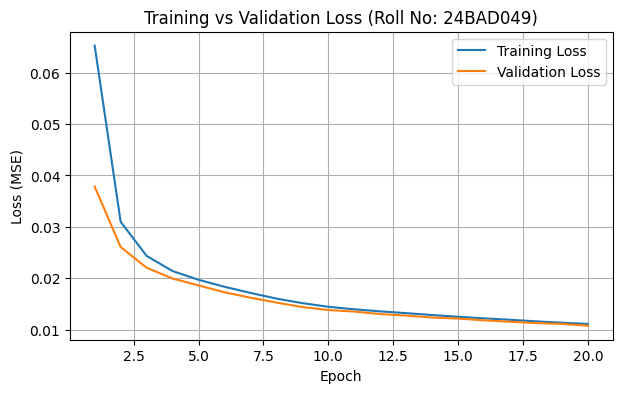

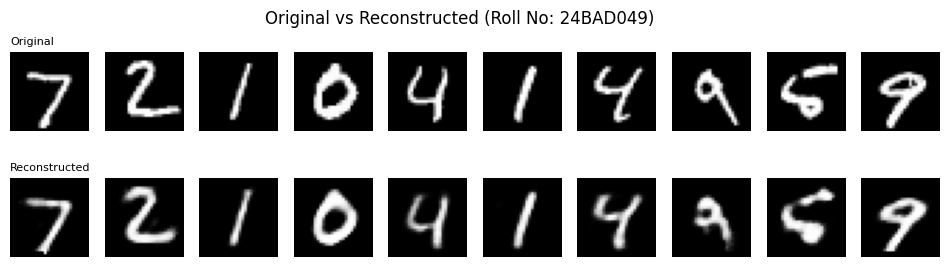

In [3]:
# Roll No: 24BAD049

import pandas as pd

print("Roll No: 24BAD049")

# 1. Train the Autoencoder (input = target; test set used for validation)
EPOCHS = 20
BATCH_SIZE = 256
history = autoencoder.fit(
    x_train, target_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, target_test)
)

# 2. Record training loss and validation loss for every epoch
history_df = pd.DataFrame({
    "Epoch": range(1, EPOCHS + 1),
    "Training Loss": history.history["loss"],
    "Validation Loss": history.history["val_loss"]
})
print("\n--- Recorded Losses ---")
print(history_df.to_string(index=False))

# 3. Evaluate on the test dataset
test_loss = autoencoder.evaluate(x_test, target_test, verbose=0)
print("\nTest Loss (MSE):", test_loss)

# 4. Calculate reconstruction MSE on the test set
reconstructed = autoencoder.predict(x_test)
reconstruction_mse = np.mean(np.square(x_test - reconstructed))
print("Reconstruction MSE:", reconstruction_mse)

# 5. Plot training and validation loss vs. epochs
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), history.history["loss"], label="Training Loss")
plt.plot(range(1, EPOCHS + 1), history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Training vs Validation Loss (Roll No: 24BAD049)")
plt.legend()
plt.grid(True)
plt.show()

# 6. Compare original images with their reconstructions
n = 10
plt.figure(figsize=(12, 3))
for i in range(n):
    plt.subplot(2, n, i + 1)                      # top row: original
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.title("Original", fontsize=8, loc="left")
    plt.subplot(2, n, n + i + 1)                  # bottom row: reconstructed
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.title("Reconstructed", fontsize=8, loc="left")
plt.suptitle("Original vs Reconstructed (Roll No: 24BAD049)")
plt.show()

## PART D: Dimensionality Reduction, Feature Visualization and Experiment Management

Roll No: 24BAD049
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
New samples input shape : (10, 784)
Autoencoder output shape: (10, 784)
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

--- Dimension Comparison ---
Original data shape   : (10000, 784)
Compressed data shape : (10000, 32)
Compression ratio     : 24.5 : 1


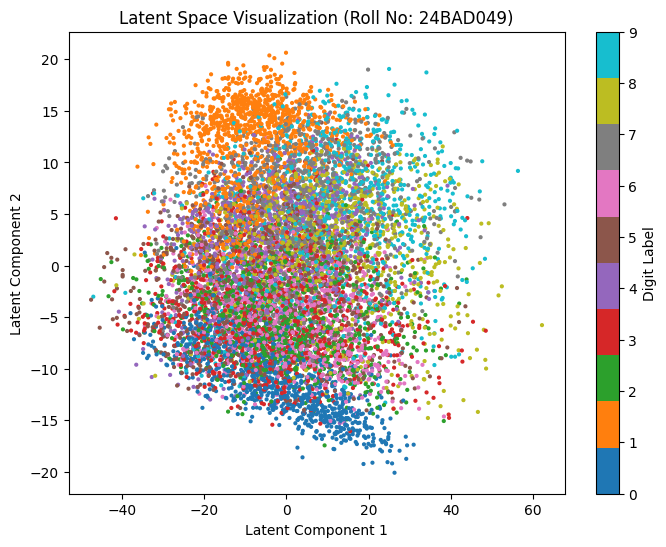

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step


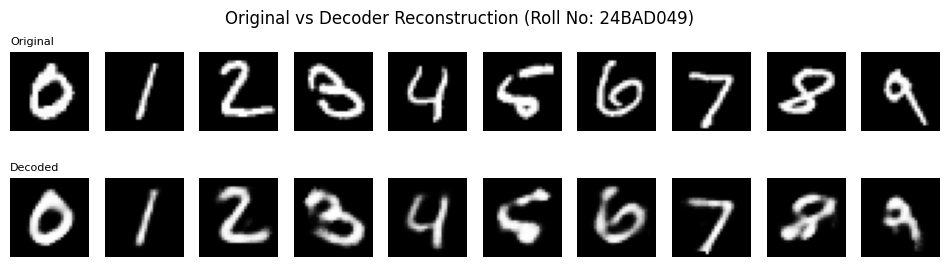


--- Observations ---
Dimensionality reduced from 784 to 32 features.
Per-digit reconstruction MSE (digits 0-9): [0.00845 0.00156 0.0143  0.02409 0.00791 0.01957 0.02469 0.00571 0.01777
 0.01678]
Mean reconstruction MSE on selected samples: 0.014082082
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Overall test reconstruction MSE: 0.010744742


In [4]:
# Roll No: 24BAD049

from sklearn.decomposition import PCA

print("Roll No: 24BAD049")

# 1. Provide new (unseen) samples to the trained model: one image per digit 0-9
#    (The sheet mentions movie reviews / LSTM, which does not apply to this
#     MNIST autoencoder, so new image samples are used instead.)
selected_idx = [np.where(y_test == d)[0][0] for d in range(10)]
new_samples = x_test[selected_idx]
new_output = autoencoder.predict(new_samples)
print("New samples input shape :", new_samples.shape)
print("Autoencoder output shape:", new_output.shape)

# 2. Extract latent-space representations of test samples using the Encoder
latent_test = encoder.predict(x_test)

# 3. Compare dimensions of original data and compressed representations
print("\n--- Dimension Comparison ---")
print("Original data shape   :", x_test.shape)
print("Compressed data shape :", latent_test.shape)
print("Compression ratio     :", x_test.shape[1] / latent_test.shape[1], ": 1")

# 4. Visualize latent representations (32-D reduced to 2-D with PCA for plotting)
latent_2d = PCA(n_components=2).fit_transform(latent_test)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(latent_2d[:, 0], latent_2d[:, 1],
                      c=y_test, cmap="tab10", s=4)
plt.colorbar(scatter, label="Digit Label")
plt.xlabel("Latent Component 1")
plt.ylabel("Latent Component 2")
plt.title("Latent Space Visualization (Roll No: 24BAD049)")
plt.show()

# 5. Reconstruct selected test samples using the Decoder and compare with originals
latent_selected = encoder.predict(new_samples)
decoded_selected = decoder.predict(latent_selected)

plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 10, i + 1)                     # top row: original
    plt.imshow(new_samples[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.title("Original", fontsize=8, loc="left")
    plt.subplot(2, 10, 10 + i + 1)                # bottom row: decoder output
    plt.imshow(decoded_selected[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.title("Decoded", fontsize=8, loc="left")
plt.suptitle("Original vs Decoder Reconstruction (Roll No: 24BAD049)")
plt.show()

# 6. Record observations (computed values)
selected_mse = np.mean(np.square(new_samples - decoded_selected), axis=1)
print("\n--- Observations ---")
print(f"Dimensionality reduced from {x_test.shape[1]} to {latent_test.shape[1]} features.")
print("Per-digit reconstruction MSE (digits 0-9):", np.round(selected_mse, 5))
print("Mean reconstruction MSE on selected samples:", selected_mse.mean())
print("Overall test reconstruction MSE:", np.mean(np.square(x_test - autoencoder.predict(x_test))))